# 共用介面示範

先依照 `GUIDELINES.md` 建立示範資料，再依序執行。這裡的圖片與模型只用來驗證流程。可複製本檔至自己的實驗資料夾。

In [1]:
from pathlib import Path
import sys

# 支援從 project/、notebooks/ 或其實驗子目錄啟動 kernel。
cwd = Path.cwd().resolve()
project_dir = next((p for p in (cwd, *cwd.parents) if (p / "models" / "registry.py").is_file() and (p / "data" / "manifest.py").is_file()), None)
if project_dir is None and (cwd / "project" / "models" / "registry.py").is_file():
    project_dir = cwd / "project"
if project_dir is None:
    raise RuntimeError("找不到 project/；請從專案目錄啟動 notebook")
if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))
print("專案目錄：", project_dir)

專案目錄： /Users/chenyingda/Documents/2027nthu/MachineLearning/final_project/project


In [2]:
from data.manifest import load_manifest, load_rgb_image
from models.registry import create_model
from PIL import Image

# 所有人共用樣本清單；正式實驗請改成共同確認的清單。
manifest = project_dir / "data" / "demo_manifest.csv"
if not manifest.exists():
    raise FileNotFoundError("請先執行 python3 project/examples/make_demo_data.py")
samples = load_manifest(manifest, split="test")
print("影像數量：", len(samples))
print("第一筆：", samples[0])

影像數量： 4
第一筆： Sample(sample_id='demo_real_1', path=PosixPath('/Users/chenyingda/Documents/2027nthu/MachineLearning/final_project/project/data/demo/demo_real_1.png'), label=0, source='toy_real', split='test')


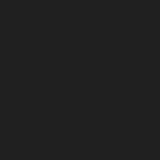

影像格式： (16, 16, 3) uint8


In [3]:
# 用共用讀圖函式載入影像。
sample = samples[0]
image = load_rgb_image(sample.path)
display(Image.fromarray(image).resize((160, 160)))
print("影像格式：", image.shape, image.dtype)

In [4]:
# 假模型以亮度當分數，數字不代表真實模型表現。
model = create_model("demo")
score = model.score_fake(image)
print(f"樣本：{sample.sample_id}，真實標籤：{sample.label}")
print(f"生成分數：{score:.3f}，預測標籤：{int(score >= model.threshold)}")

樣本：demo_real_1，真實標籤：0
生成分數：0.125，預測標籤：0


## 接下來

在自己的實驗目錄探索；確認後將正式邏輯整理到對應的 `experiments/`。記錄使用的模型、樣本清單與參數。